In [2]:
pip install persim

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.6/48.6 kB 2.1 MB/s eta 0:00:00
  Created wheel for hopcroftkarp: filename=hopcroftkarp-1.2.5-py2.py3-none-any.whl size=18104 sha256=64569ff595283eff715324024cd5468ed31e4a79ab538a6ac2d3e4f9602ef9b0
  Stored in directory: /root/.cache/pip/wheels/2a/fd/fe/f4b8fd82894e1d9e04040ef41dc5ae6eb7a8e9b0ef5a9402fe
Successfully built hopcroftkarp


In [4]:
import numpy as np
from persim import bottleneck

D1 = np.array([
    [1.0, 3.0],
    [2.0, 7.0],
    [5.0, 6.0],
    [7.0, 8.0]
])

D2 = np.array([
    [2.0, 5.0],
    [3.0, 7.0],
    [6.0, 9.0]
])

# Вернёт расстояние; matching=True может вернуть соответствие
dist = bottleneck(D1, D2, matching=False)
print("Bottleneck distance:", dist)

Bottleneck distance: 1.5


In [ ]:
dist, matching = bottleneck(D1, D2, matching=True)
print(matching)

1.5
[[ 0.  -1.   1. ]
 [ 1.   1.   1. ]
 [ 2.  -1.   0.5]
 [ 3.   2.   1. ]
 [-1.   0.   1.5]]


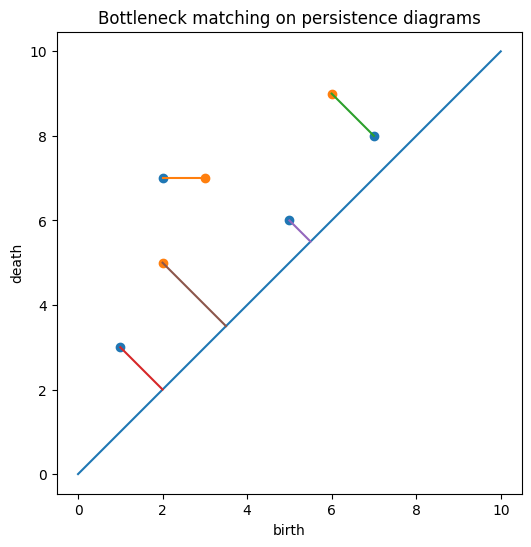

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Points from the example
D1 = np.array([
    [1.0, 3.0],
    [2.0, 7.0],
    [5.0, 6.0],
    [7.0, 8.0]
])

D2 = np.array([
    [2.0, 5.0],
    [3.0, 7.0],
    [6.0, 9.0]
])

# Matching pairs (from persim output)
real_pairs = [
    (D1[1], D2[1]),  # (2,7) ↔ (3,7)
    (D1[3], D2[2])   # (7,8) ↔ (6,9)
]

# Diagonal projections for points sent to diagonal
diag_proj = lambda p: np.array([(p[0] + p[1]) / 2, (p[0] + p[1]) / 2])

diag_points = [
    D1[0], D1[2], D2[0]
]

proj_points = [diag_proj(p) for p in diag_points]

# Plot
plt.figure(figsize=(6,6))

plt.scatter(D1[:,0], D1[:,1])
plt.scatter(D2[:,0], D2[:,1])

# Diagonal line
x = np.linspace(0,10,100)
plt.plot(x, x)

# Lines for real matchings
for p, q in real_pairs:
    plt.plot([p[0], q[0]], [p[1], q[1]])

# Lines to diagonal
for p, q in zip(diag_points, proj_points):
    plt.plot([p[0], q[0]], [p[1], q[1]])

plt.xlabel("birth")
plt.ylabel("death")
plt.title("Bottleneck matching on persistence diagrams")
plt.axis("equal")
plt.show()
